In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

In [11]:
df = pd.read_excel("../Data/Original/Food_Waste_Prediction_Dataset (1).xlsx")
df_raw = df.copy()
print("--DATASET LOADED--")
print(f"rows: {df.shape[0]}, Colums: {df.shape[1]}")
print("--5--")
display(df.head(3))
print("--5--")
display(df.tail(3))
print("samply")
display(df.sample(3))

--DATASET LOADED--
rows: 1000, Colums: 16
--5--


,Restaurant_ID,Restaurant_Name,City,Cuisine,Food_Item,Date,Prepared_Quantity,Sold_Quantity,Remaining_Quantity,Temperature_C,Weather,Weekend,Holiday,Discount_Percent,Customers,Waste_Amount_kg
0,R001,Spice Garden,Chennai,South Indian,Pongal,2025-05-06,107,102,5,25,Cloudy,No,No,20,121,1.09
1,R005,Green Bowl,Mumbai,South Indian,Dosa,2025-11-29,229,198,31,29,Sunny,Yes,No,10,102,5.61
2,R002,Urban Bites,Bengaluru,Italian,Pasta,2025-05-23,89,89,0,32,Sunny,No,No,15,54,0.00


--5--


,Restaurant_ID,Restaurant_Name,City,Cuisine,Food_Item,Date,Prepared_Quantity,Sold_Quantity,Remaining_Quantity,Temperature_C,Weather,Weekend,Holiday,Discount_Percent,Customers,Waste_Amount_kg
997,R001,Spice Garden,Chennai,South Indian,Idli,2025-07-01,293,267,26,35,Cloudy,No,No,25,135,5.96
998,R004,Food Hub,Coimbatore,North Indian,Biryani,2025-04-04,235,164,71,38,Sunny,No,No,0,95,17.36
999,R004,Food Hub,Coimbatore,North Indian,Biryani,2025-10-29,121,92,29,25,Sunny,No,No,15,72,8.00


samply


,Restaurant_ID,Restaurant_Name,City,Cuisine,Food_Item,Date,Prepared_Quantity,Sold_Quantity,Remaining_Quantity,Temperature_C,Weather,Weekend,Holiday,Discount_Percent,Customers,Waste_Amount_kg
167,R004,Food Hub,Coimbatore,North Indian,Biryani,2025-05-05,58,53,5,25,Sunny,No,No,15,42,1.03
318,R004,Food Hub,Coimbatore,North Indian,Naan,2025-04-03,249,184,65,32,Cloudy,No,No,5,128,14.01
393,R001,Spice Garden,Chennai,South Indian,Meals,2025-07-25,207,164,43,31,Cloudy,No,No,20,186,13.40


In [ ]:
print(f"--- SHAPE: {df.shape[0]} rows x {df.shape[1]} columns ---")
print("--- INFO ---")
df.info()

# Split the columns by type
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"\nNumerical columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Text columns ({len(text_cols)}): {text_cols}")

--- SHAPE: 1000 rows x 16 columns ---
--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Restaurant_ID       1000 non-null   str    
 1   Restaurant_Name     1000 non-null   str    
 2   City                1000 non-null   str    
 3   Cuisine             1000 non-null   str    
 4   Food_Item           1000 non-null   str    
 5   Date                1000 non-null   str    
 6   Prepared_Quantity   1000 non-null   int64  
 7   Sold_Quantity       1000 non-null   int64  
 8   Remaining_Quantity  1000 non-null   int64  
 9   Temperature_C       1000 non-null   int64  
 10  Weather             1000 non-null   str    
 11  Weekend             1000 non-null   str    
 12  Holiday             1000 non-null   str    
 13  Discount_Percent    1000 non-null   int64  
 14  Customers           1000 non-null   int64  
 15  Waste_Amount_kg 

In [ ]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"\nNumerical columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Text columns ({len(text_cols)}): {text_cols}")

print("--- DESCRIBE (NUMERICAL COLUMNS) ---")
display(df.describe().T.round(1))

print("--- NUNIQUE ---")
display(df.nunique().sort_values(ascending=False).to_frame("unique_values"))


Numerical columns (7): ['Prepared_Quantity', 'Sold_Quantity', 'Remaining_Quantity', 'Temperature_C', 'Discount_Percent', 'Customers', 'Waste_Amount_kg']
Text columns (9): ['Restaurant_ID', 'Restaurant_Name', 'City', 'Cuisine', 'Food_Item', 'Date', 'Weather', 'Weekend', 'Holiday']
--- DESCRIBE (NUMERICAL COLUMNS) ---


,count,mean,std,min,25%,50%,75%,max
Prepared_Quantity,1000.0,174.9,72.4,50.0,111.0,177.0,239.0,300.0
Sold_Quantity,1000.0,139.0,61.2,18.0,86.0,139.0,189.0,294.0
Remaining_Quantity,1000.0,35.9,24.2,0.0,17.0,33.0,53.0,112.0
Temperature_C,1000.0,31.2,5.5,22.0,26.0,32.0,36.0,40.0
Discount_Percent,1000.0,13.1,8.6,0.0,5.0,15.0,20.0,25.0
Customers,1000.0,98.8,55.0,11.0,56.0,90.0,128.2,320.0
Waste_Amount_kg,1000.0,9.5,6.7,0.0,4.4,8.4,14.0,34.1


--- NUNIQUE ---


,unique_values
Waste_Amount_kg,766
Date,336
Prepared_Quantity,249
Sold_Quantity,242
Customers,224
Remaining_Quantity,103
Temperature_C,19
Food_Item,12
Discount_Percent,6
Restaurant_ID,5


In [ ]:
# Count and percentage of missing values per column
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(1),
})
print("--- COLUMNS WITH MISSING VALUES ---")
display(missing[missing["missing_count"] > 0])
print(f"Total missing cells: {df.isnull().sum().sum()}")

--- COLUMNS WITH MISSING VALUES ---


,missing_count,missing_pct


Total missing cells: 0


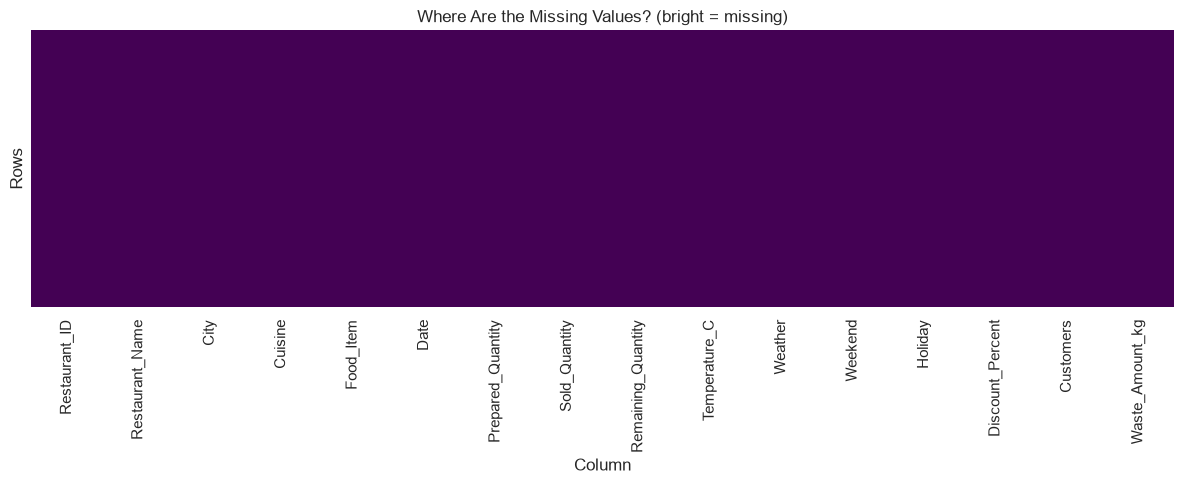

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Where Are the Missing Values? (bright = missing)")
plt.xlabel("Column")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()

In [ ]:
for col in ["Restaurant_ID", "Restaurant_Name", "City", "Cuisine", "Food_Item", "Weather", "Weekend", "Holiday"]:
    print(f"--- {col} ---")
    display(df[col].map(repr).value_counts().to_frame("rows"))

--- Restaurant_ID ---


,rows
Restaurant_ID,
'R002',216
'R001',211
'R004',200
'R003',191
'R005',182


--- Restaurant_Name ---


,rows
Restaurant_Name,
'Urban Bites',216
'Spice Garden',211
'Food Hub',200
'Ocean Treat',191
'Green Bowl',182


--- City ---


,rows
City,
'Bengaluru',216
'Chennai',211
'Coimbatore',200
'Hyderabad',191
'Mumbai',182


... (6 outputs left out)

--- Weekend ---


,rows
Weekend,
'No',723
'Yes',277


--- Holiday ---


,rows
Holiday,
'No',929
'Yes',71


In [ ]:
duplicate_count = df.duplicated().sum()
print(f"--- DUPLICATE ROWS: {duplicate_count} ---")
display(df[df.duplicated(keep=False)])

--- DUPLICATE ROWS: 0 ---


,Restaurant_ID,Restaurant_Name,City,Cuisine,Food_Item,Date,Prepared_Quantity,Sold_Quantity,Remaining_Quantity,Temperature_C,Weather,Weekend,Holiday,Discount_Percent,Customers,Waste_Amount_kg


In [ ]:
suspects = ["Date", "Weekend", "Holiday"]
display(df[suspects].head())
display(df[suspects].dtypes.to_frame("dtype"))

,Date,Weekend,Holiday
0,2025-05-06,No,No
1,2025-11-29,Yes,No
2,2025-05-23,No,No
3,2025-02-10,No,No
4,2025-02-21,No,No


,dtype
Date,str
Weekend,str
Holiday,str


In [ ]:
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
yes_no = {"Yes": 1, "No": 0}
for col in ["Weekend", "Holiday"]:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].map(yes_no)

In [ ]:
display(df[suspects].dtypes.to_frame("dtype"))
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Missing after conversion: Weekend = {df['Weekend'].isnull().sum()}, Holiday = {df['Holiday'].isnull().sum()}")
display(df[["Weekend", "Holiday"]].value_counts().to_frame("rows"))

,dtype
Date,datetime64[us]
Weekend,int64
Holiday,int64


Date range: 2025-01-02 to 2025-12-31
Missing after conversion: Weekend = 0, Holiday = 0


,,rows
Weekend,Holiday,
0,0,669
1,0,260
0,1,54
1,1,17


In [ ]:
for col in ["Restaurant_ID", "Restaurant_Name", "City", "Cuisine", "Food_Item", "Weather"]:
    cleaned = df[col].str.strip().str.lower()
    print(f"{col}: nunique raw = {df[col].nunique()}, after strip + lower = {cleaned.nunique()}")

Restaurant_ID: nunique raw = 5, after strip + lower = 5
Restaurant_Name: nunique raw = 5, after strip + lower = 5
City: nunique raw = 5, after strip + lower = 5
Cuisine: nunique raw = 4, after strip + lower = 4
Food_Item: nunique raw = 12, after strip + lower = 12
Weather: nunique raw = 3, after strip + lower = 3


In [ ]:
rules = {
    "Sold_Quantity > Prepared_Quantity": df["Sold_Quantity"] > df["Prepared_Quantity"],
    "Remaining != Prepared - Sold": df["Remaining_Quantity"] != df["Prepared_Quantity"] - df["Sold_Quantity"],
    "Waste_Amount_kg < 0": df["Waste_Amount_kg"] < 0,
    "Customers <= 0": df["Customers"] <= 0,
    "Discount_Percent outside 0-100": ~df["Discount_Percent"].between(0, 100),
    "Temperature_C outside 0-50": ~df["Temperature_C"].between(0, 50),
}
print("--- ROWS BREAKING EACH RULE ---")
display(pd.Series({name: int(mask.sum()) for name, mask in rules.items()}).to_frame("rows"))

--- ROWS BREAKING EACH RULE ---


,rows
Sold_Quantity > Prepared_Quantity,0
Remaining != Prepared - Sold,0
Waste_Amount_kg < 0,0
Customers <= 0,0
Discount_Percent outside 0-100,0
Temperature_C outside 0-50,0


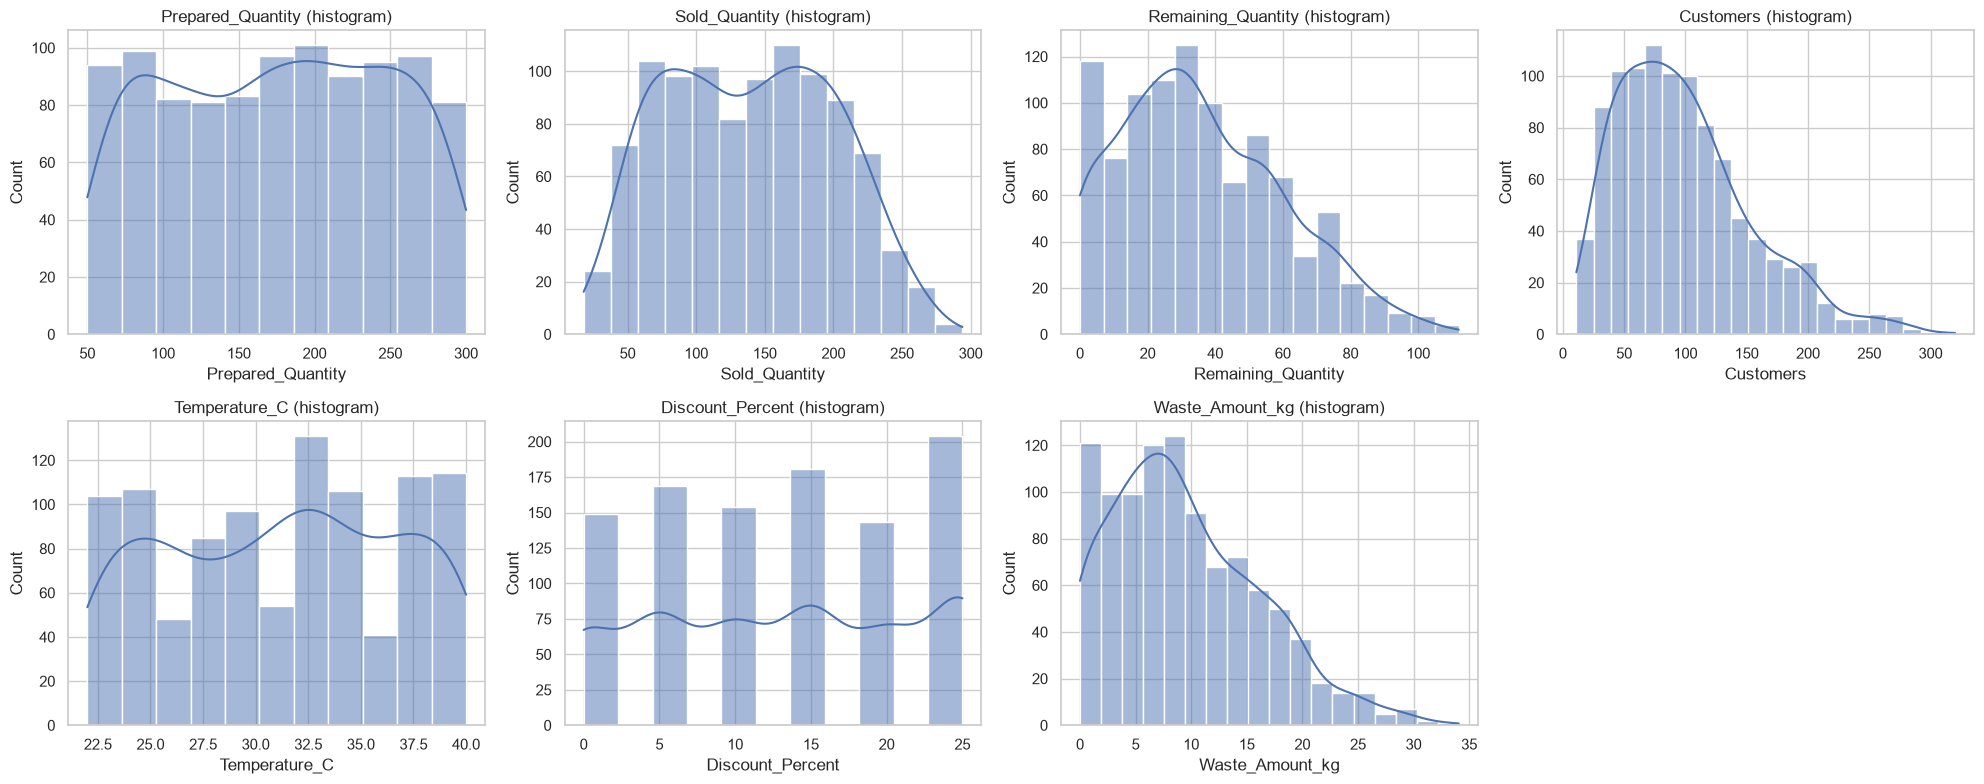

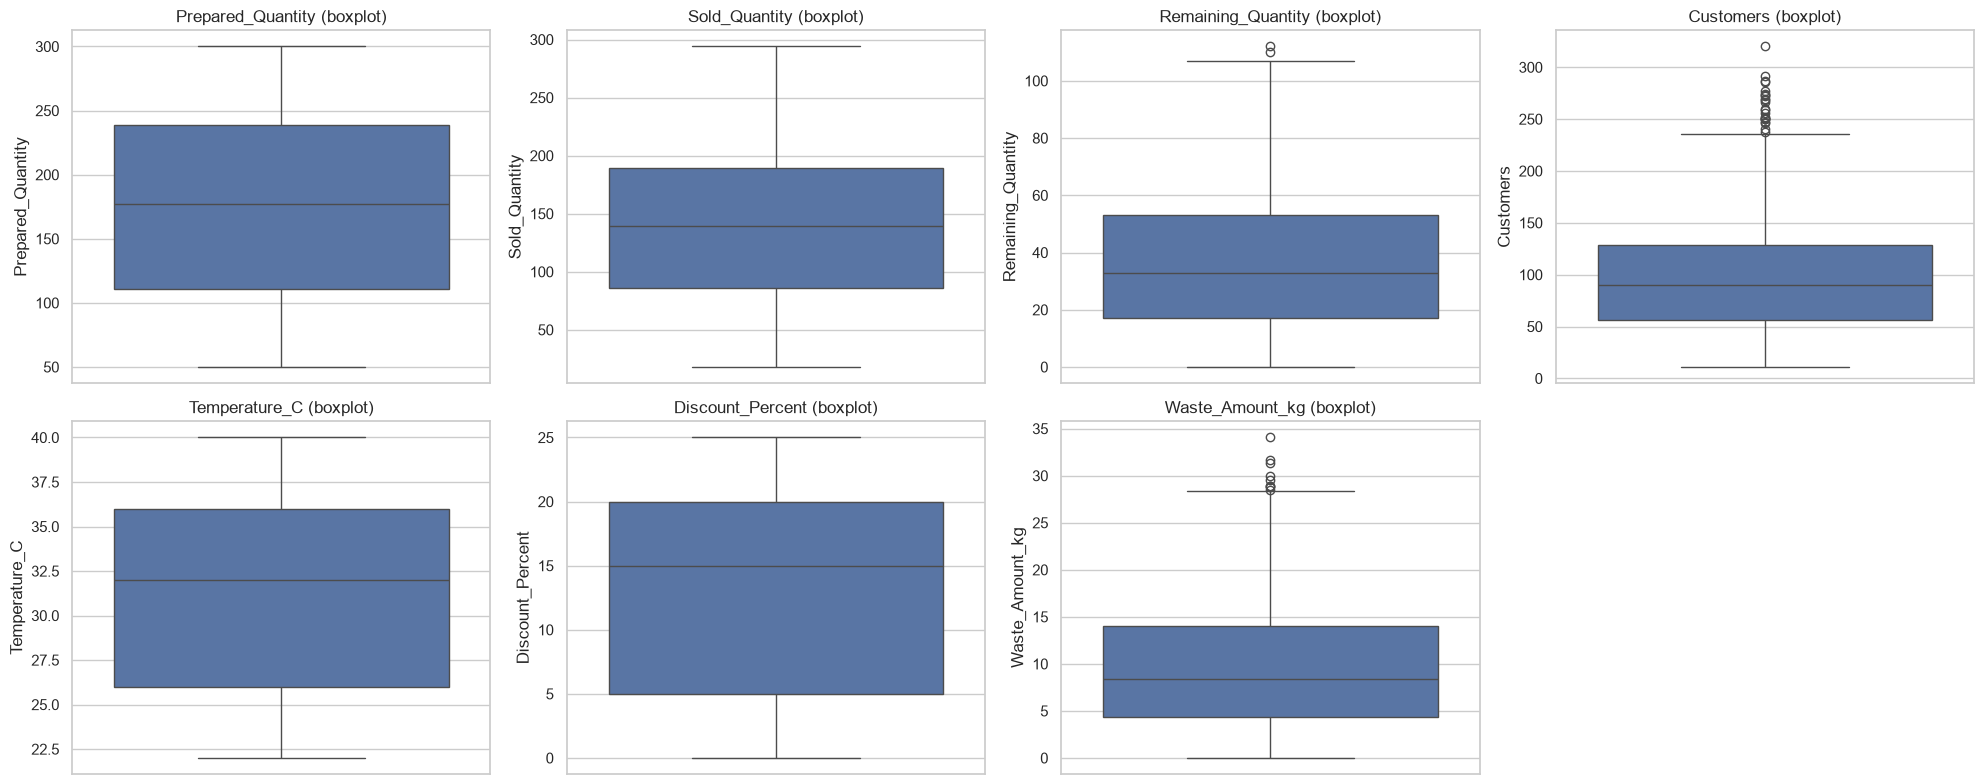

In [ ]:
num_cols_eda = ["Prepared_Quantity", "Sold_Quantity", "Remaining_Quantity", "Customers", "Temperature_C", "Discount_Percent", "Waste_Amount_kg"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, num_cols_eda):
    sns.histplot(df[col], kde=True, ax=ax).set(title=f"{col} (histogram)")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, num_cols_eda):
    sns.boxplot(y=df[col], ax=ax).set(title=f"{col} (boxplot)")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
print("--- SKEWNESS TABLE ---")
display(df[num_cols_eda].skew().sort_values(ascending=False).round(2).to_frame("skewness"))
print(f"Waste_Amount_kg: mean = {df['Waste_Amount_kg'].mean():.2f}, median = {df['Waste_Amount_kg'].median():.2f}, skew = {df['Waste_Amount_kg'].skew():.2f}")
print(f"Rows with Waste_Amount_kg = 0: {(df['Waste_Amount_kg'] == 0).sum()}")

--- SKEWNESS TABLE ---


,skewness
Customers,0.92
Waste_Amount_kg,0.69
Remaining_Quantity,0.52
Sold_Quantity,0.09
Prepared_Quantity,-0.03
Discount_Percent,-0.04
Temperature_C,-0.06


Waste_Amount_kg: mean = 9.50, median = 8.38, skew = 0.69
Rows with Waste_Amount_kg = 0: 69


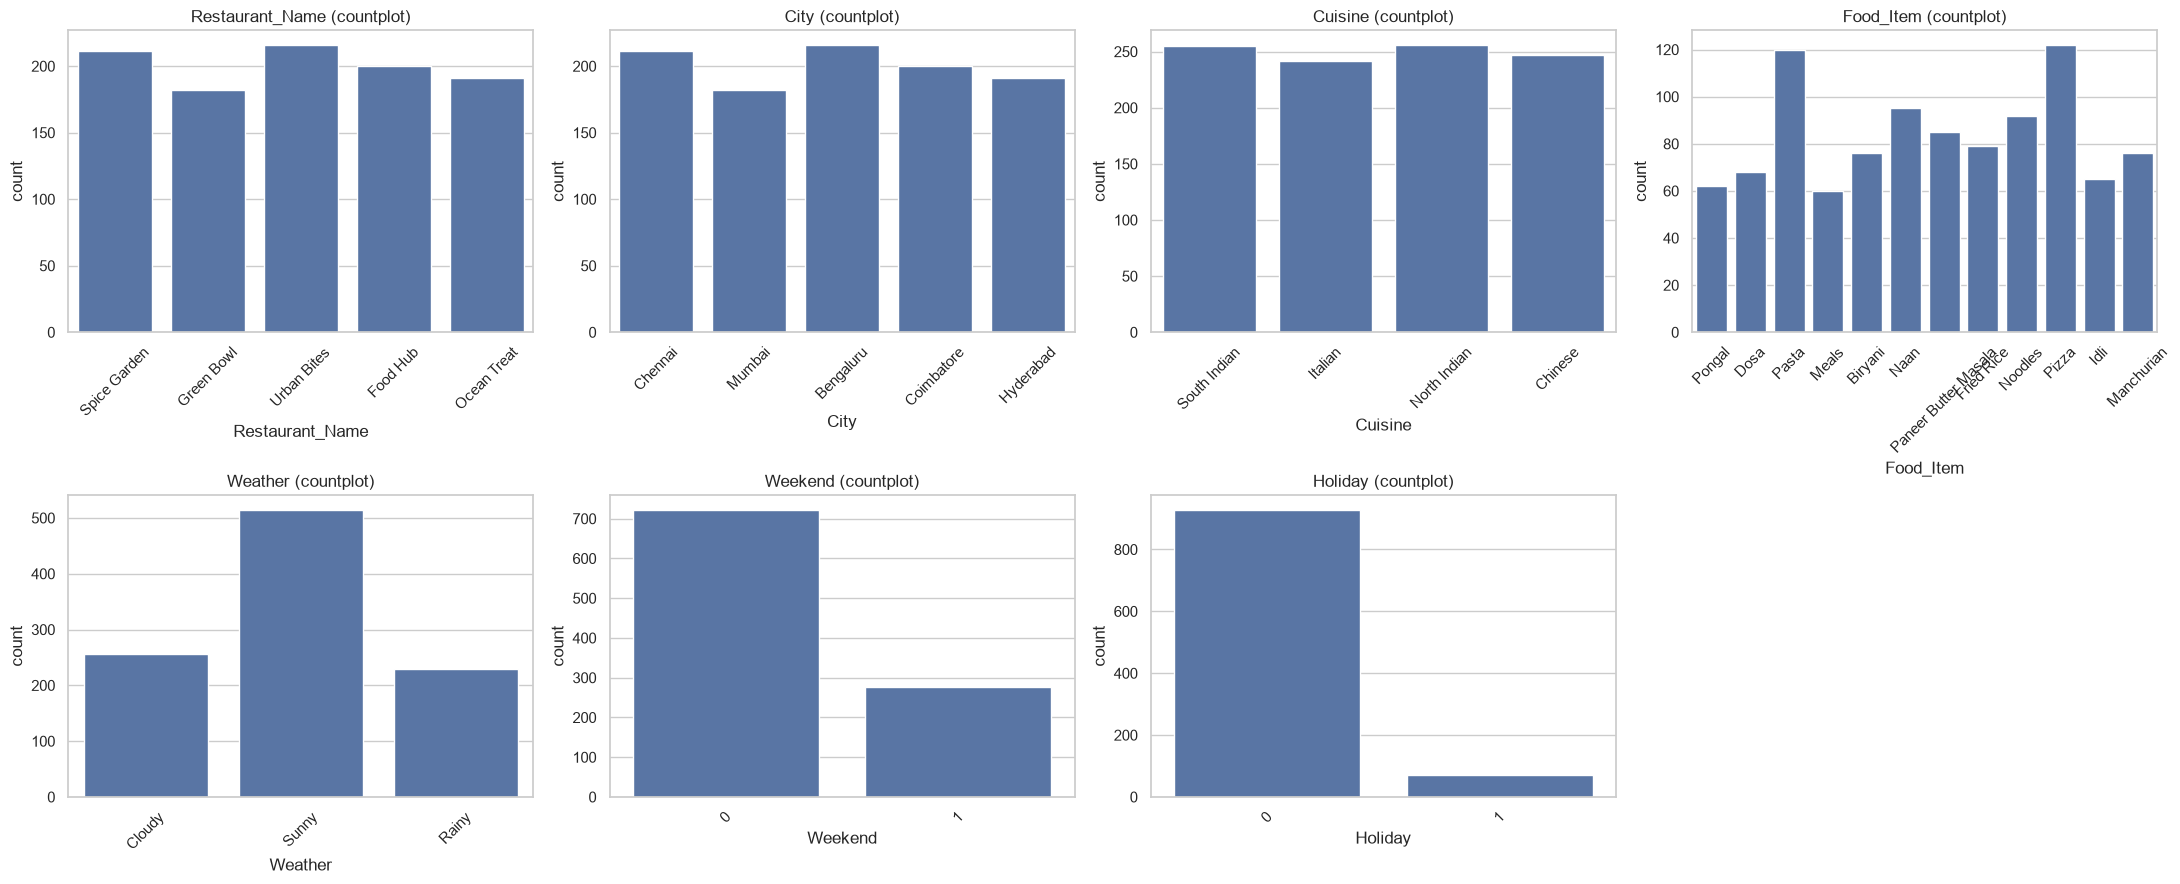

In [ ]:
cat_cols_eda = ["Restaurant_Name", "City", "Cuisine", "Food_Item", "Weather", "Weekend", "Holiday"]
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.flat, cat_cols_eda):
    sns.countplot(data=df, x=col, ax=ax).set(title=f"{col} (countplot)")
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Do Restaurant_ID, Restaurant_Name and City say the same thing?
display(df.groupby("Restaurant_ID")[["Restaurant_Name", "City"]].nunique())

,Restaurant_Name,City
Restaurant_ID,,
R001,1,1
R002,1,1
R003,1,1
R004,1,1
R005,1,1


In [ ]:
df = df.drop(columns=["Restaurant_ID", "Restaurant_Name"])
print(f"Remaining columns ({df.shape[1]}): {df.columns.tolist()}")

Remaining columns (14): ['City', 'Cuisine', 'Food_Item', 'Date', 'Prepared_Quantity', 'Sold_Quantity', 'Remaining_Quantity', 'Temperature_C', 'Weather', 'Weekend', 'Holiday', 'Discount_Percent', 'Customers', 'Waste_Amount_kg']


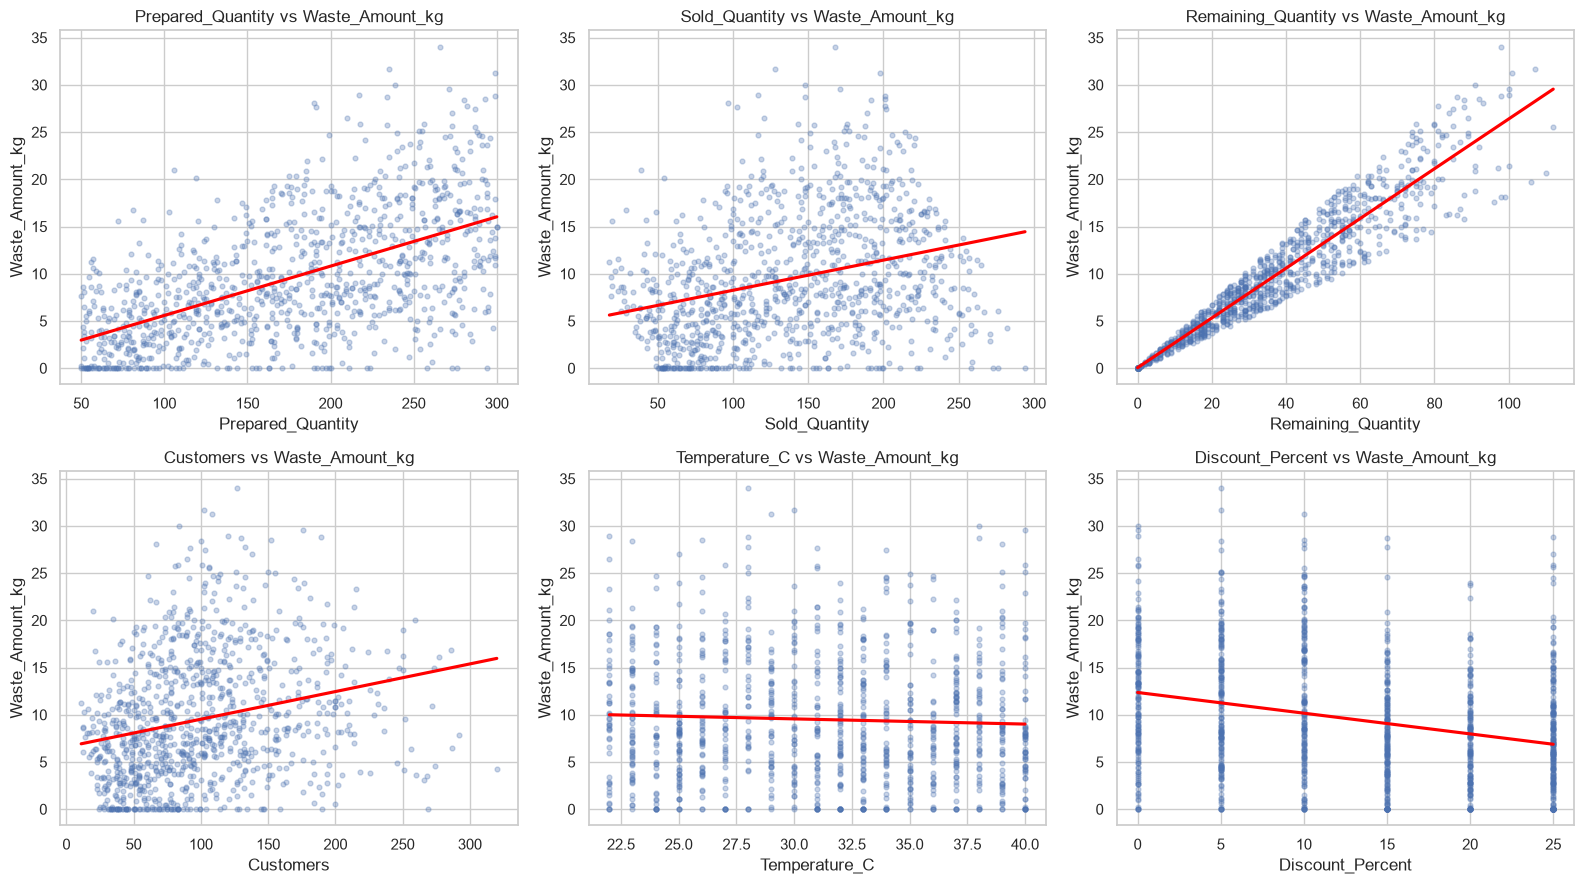

In [ ]:
features = ["Prepared_Quantity", "Sold_Quantity", "Remaining_Quantity", "Customers", "Temperature_C", "Discount_Percent"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, features):
    sns.regplot(data=df, x=col, y="Waste_Amount_kg", ci=None, scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{col} vs Waste_Amount_kg")
plt.tight_layout()
plt.show()

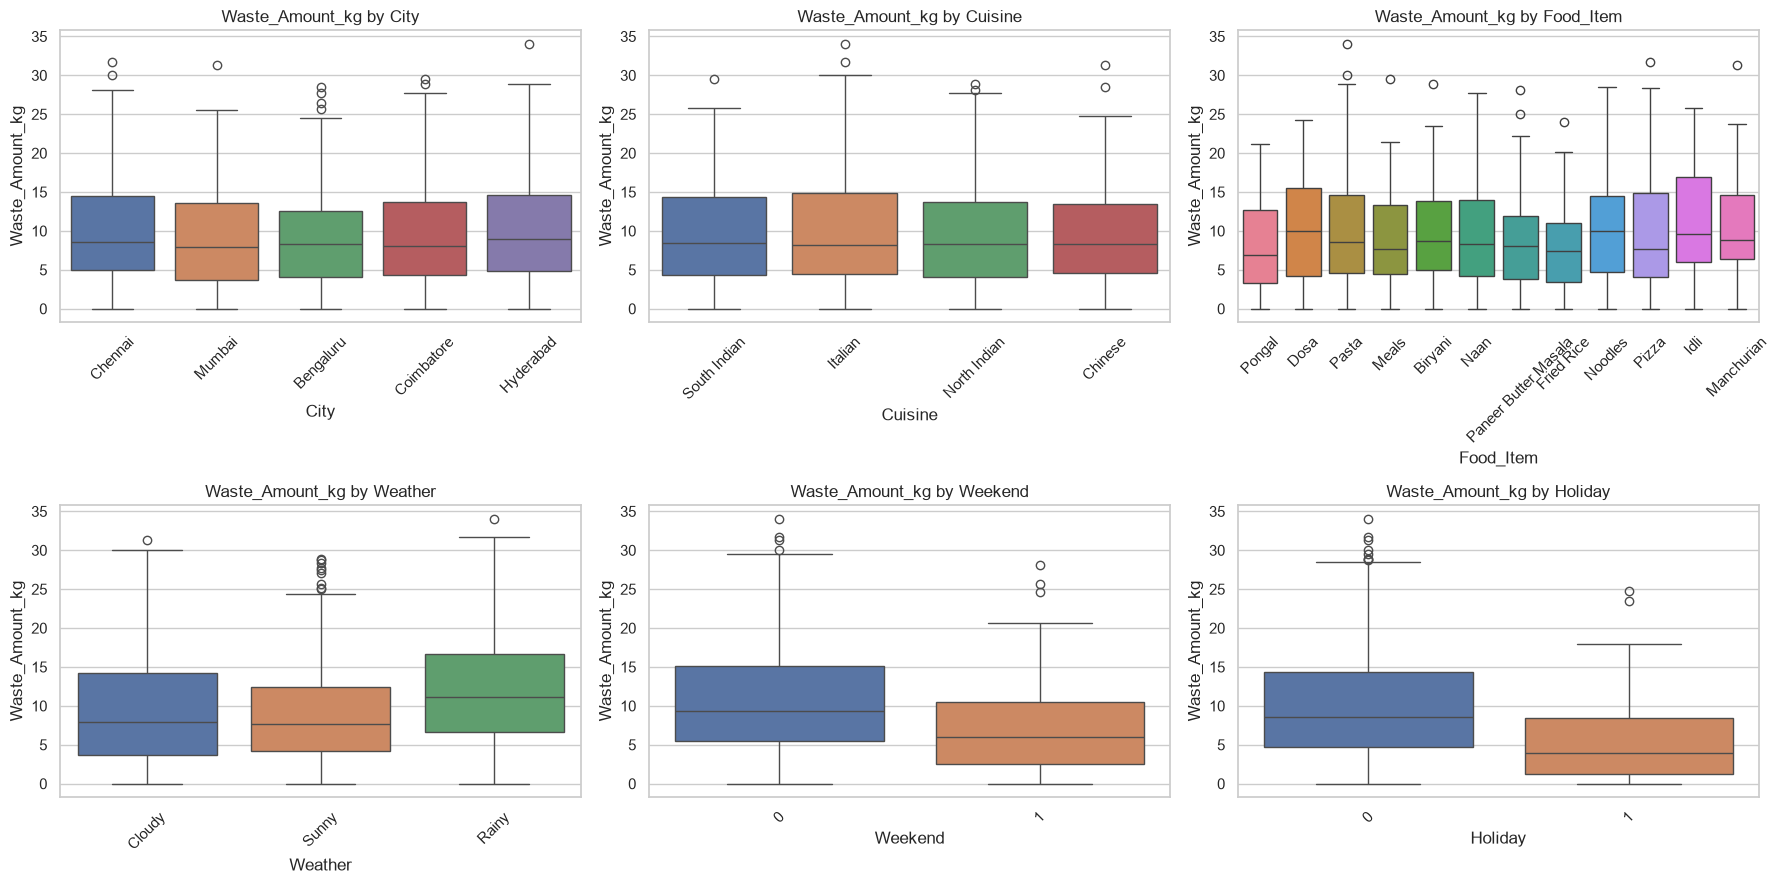

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ["City", "Cuisine", "Food_Item", "Weather", "Weekend", "Holiday"]):
    sns.boxplot(data=df, x=col, y="Waste_Amount_kg", hue=col, legend=False, ax=ax)
    ax.set_title(f"Waste_Amount_kg by {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

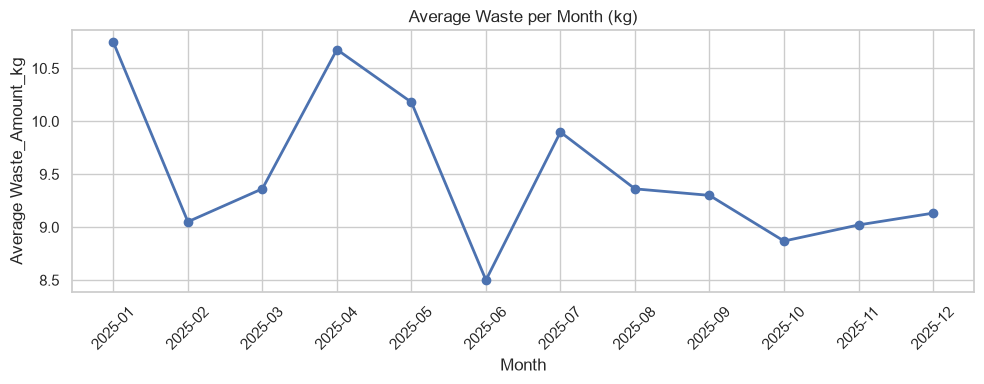

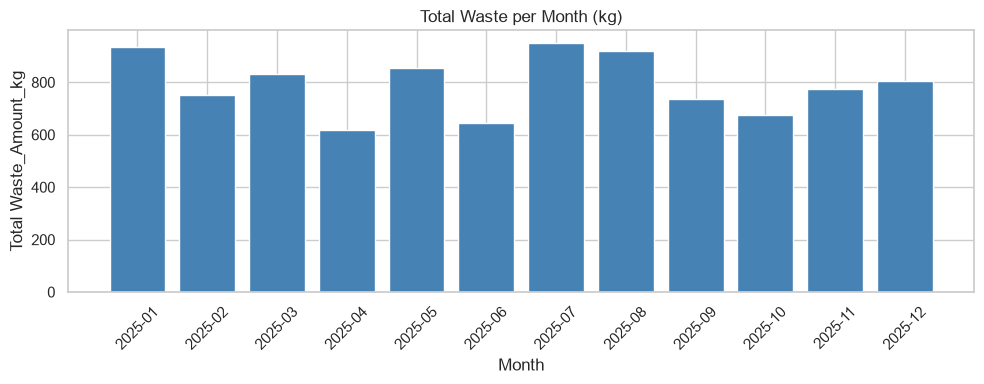

In [ ]:
monthly = df.groupby(df["Date"].dt.to_period("M"))["Waste_Amount_kg"].mean()
plt.figure(figsize=(10, 4))
plt.plot(monthly.index.astype(str), monthly.values, marker="o", linewidth=2)
plt.title("Average Waste per Month (kg)")
plt.xlabel("Month")
plt.ylabel("Average Waste_Amount_kg")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Total waste per month (kg)
monthly_total = df.groupby(df["Date"].dt.to_period("M"))["Waste_Amount_kg"].sum()
plt.figure(figsize=(10, 4))
plt.bar(monthly_total.index.astype(str), monthly_total.values, color="steelblue")
plt.title("Total Waste per Month (kg)")
plt.xlabel("Month")
plt.ylabel("Total Waste_Amount_kg")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

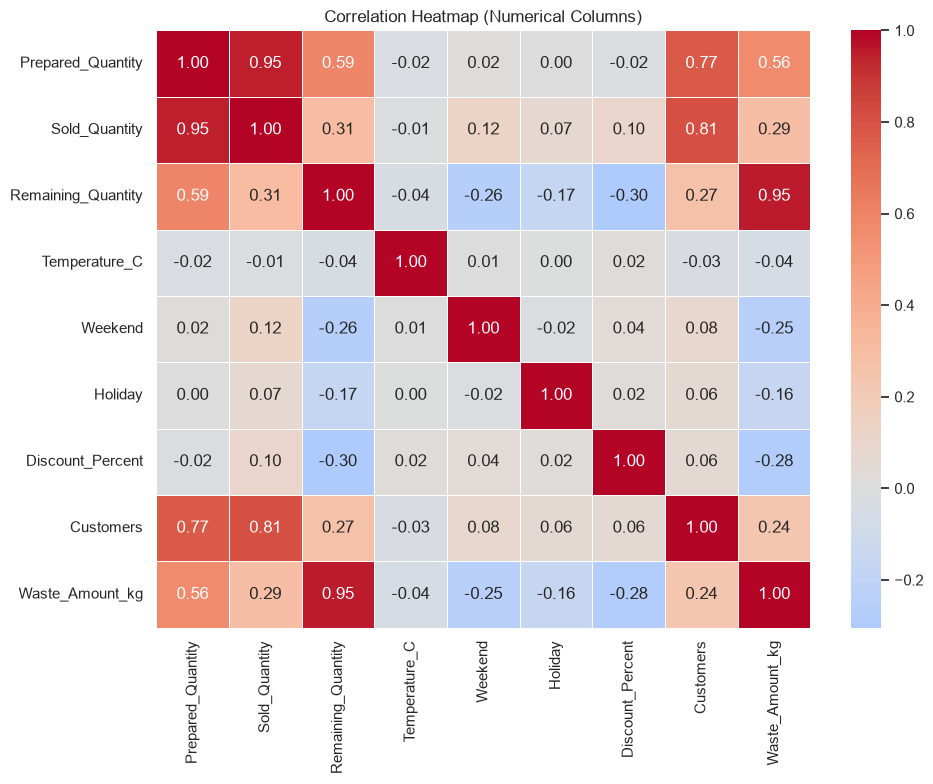

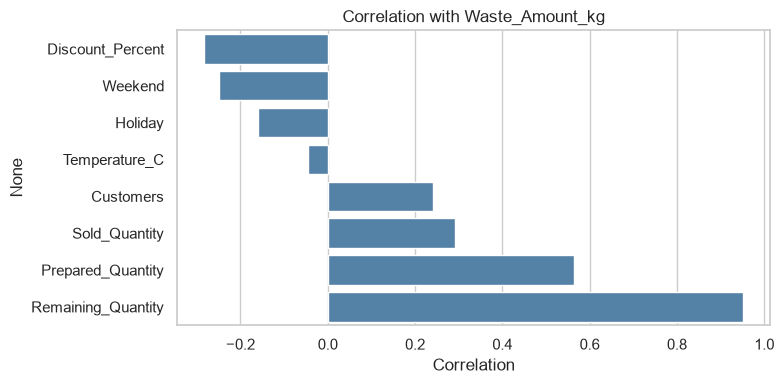

Waste / Remaining is always between 0.18 and 0.35
Rows with Remaining = 0 and Waste = 0: 69


In [ ]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap (Numerical Columns)")
plt.tight_layout()
plt.show()

target_corr = corr["Waste_Amount_kg"].drop("Waste_Amount_kg").sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=target_corr.values, y=target_corr.index, color="steelblue")
plt.title("Correlation with Waste_Amount_kg")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

ratio = df["Waste_Amount_kg"] / df["Remaining_Quantity"].replace(0, np.nan)
print(f"Waste / Remaining is always between {ratio.min():.2f} and {ratio.max():.2f}")
print(f"Rows with Remaining = 0 and Waste = 0: {((df['Remaining_Quantity'] == 0) & (df['Waste_Amount_kg'] == 0)).sum()}")

In [ ]:
# Target leakage: drop these two columns
df = df.drop(columns=["Remaining_Quantity", "Sold_Quantity"])
print(f"Remaining columns ({df.shape[1]}): {df.columns.tolist()}")

Remaining columns (12): ['City', 'Cuisine', 'Food_Item', 'Date', 'Prepared_Quantity', 'Temperature_C', 'Weather', 'Weekend', 'Holiday', 'Discount_Percent', 'Customers', 'Waste_Amount_kg']


In [ ]:
cols = ["Prepared_Quantity", "Customers", "Waste_Amount_kg"]
q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
table = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": low, "upper_fence": high})
table["n_outside"] = ((df[cols] < low) | (df[cols] > high)).sum()
print("--- IQR OUTLIER TABLE ---")
display(table.round(1))

--- IQR OUTLIER TABLE ---


,Q1,Q3,IQR,lower_fence,upper_fence,n_outside
Prepared_Quantity,111.0,239.0,128.0,-81.0,431.0,0
Customers,56.0,128.2,72.2,-52.4,236.6,23
Waste_Amount_kg,4.4,14.0,9.6,-10.1,28.4,9


In [ ]:
df["month"] = df["Date"].dt.month

day_of_week = df["Date"].dt.day_of_week   
display(pd.crosstab(day_of_week, df["Weekend"]))

df = df.drop(columns=["Date"])
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

Weekend,0,1
Date,,
0,150,0
1,133,0
2,141,0
3,155,0
4,144,0
5,0,145
6,0,132


Shape: (1000, 12)
Columns: ['City', 'Cuisine', 'Food_Item', 'Prepared_Quantity', 'Temperature_C', 'Weather', 'Weekend', 'Holiday', 'Discount_Percent', 'Customers', 'Waste_Amount_kg', 'month']


In [ ]:
X = df.drop(columns=["Waste_Amount_kg"])
y = df["Waste_Amount_kg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- SHAPES ---")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")
print(f"Test share: {len(X_test) / len(X):.1%}")

--- SHAPES ---
X_train: (800, 11) | y_train: (800,)
X_test:  (200, 11) | y_test:  (200,)
Test share: 20.0%


In [ ]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"Numerical: {num_cols}")
print(f"Text: {cat_cols}")

# Near-constant columns (learned on TRAIN)
top_share = X_train.apply(lambda s: s.value_counts(normalize=True).iloc[0])
near_const = top_share[top_share > 0.99].index.tolist()
print(f"Near-constant columns dropped: {near_const}")
X_train = X_train.drop(columns=near_const)
X_test = X_test.drop(columns=near_const)
num_cols = [c for c in num_cols if c not in near_const]
cat_cols = [c for c in cat_cols if c not in near_const]

# Missing values (none now, but the imputers make the pipeline safe for new data)
num_imp = SimpleImputer(strategy="median").fit(X_train[num_cols])
cat_imp = SimpleImputer(strategy="most_frequent").fit(X_train[cat_cols])
for part in (X_train, X_test):
    part[num_cols] = num_imp.transform(part[num_cols])
    part[cat_cols] = cat_imp.transform(part[cat_cols])
print(f"Missing values left: train = {X_train.isnull().sum().sum()}, test = {X_test.isnull().sum().sum()}")

Numerical: ['Prepared_Quantity', 'Temperature_C', 'Weekend', 'Holiday', 'Discount_Percent', 'Customers', 'month']
Text: ['City', 'Cuisine', 'Food_Item', 'Weather']
Near-constant columns dropped: []
Missing values left: train = 0, test = 0


In [ ]:
# Clip the continuous columns with IQR fences learned from TRAIN only
cont_cols = ["Prepared_Quantity", "Customers"]
q1, q3 = X_train[cont_cols].quantile(0.25), X_train[cont_cols].quantile(0.75)
clip_low, clip_high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
clipped_train = (X_train[cont_cols].lt(clip_low) | X_train[cont_cols].gt(clip_high)).sum().sum()
clipped_test = (X_test[cont_cols].lt(clip_low) | X_test[cont_cols].gt(clip_high)).sum().sum()
X_train[cont_cols] = X_train[cont_cols].clip(clip_low, clip_high, axis=1)
X_test[cont_cols] = X_test[cont_cols].clip(clip_low, clip_high, axis=1)
print(f"Values clipped at the train fences: train = {clipped_train}, test = {clipped_test}")

Values clipped at the train fences: train = 18, test = 7


In [ ]:
# One-hot encoding of the text columns (categories learned from TRAIN)
ohe = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
ohe = ohe.set_output(transform="pandas").fit(X_train[cat_cols])
train_dummies = ohe.transform(X_train[cat_cols])
test_dummies = ohe.transform(X_test[cat_cols])
X_train = pd.concat([X_train.drop(columns=cat_cols), train_dummies], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), test_dummies], axis=1)
print(f"Columns after encoding: {X_train.shape[1]} (one-hot columns: {train_dummies.shape[1]})")

Columns after encoding: 27 (one-hot columns: 20)


In [ ]:
# Standard scaling (mean 0, std 1), learned from TRAIN
scaler = StandardScaler().fit(X_train)
X_train_ready = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_ready = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
display(X_train_ready.iloc[:, :5].agg(["mean", "std"]).round(2))

,Prepared_Quantity,Temperature_C,Weekend,Holiday,Discount_Percent
mean,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


In [ ]:
assert X_train_ready.isnull().sum().sum() == 0 and X_test_ready.isnull().sum().sum() == 0
assert list(X_train_ready.columns) == list(X_test_ready.columns)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train_ready.dtypes)
assert len(X_train_ready) == len(y_train) and len(X_test_ready) == len(y_test)
print("All checks passed: no NaN, same columns, all numeric.")
print(f"X_train_ready: {X_train_ready.shape} | X_test_ready: {X_test_ready.shape}")
print(f"Columns: {X_train_ready.columns.tolist()}")

All checks passed: no NaN, same columns, all numeric.
X_train_ready: (800, 27) | X_test_ready: (200, 27)
Columns: ['Prepared_Quantity', 'Temperature_C', 'Weekend', 'Holiday', 'Discount_Percent', 'Customers', 'month', 'City_Chennai', 'City_Coimbatore', 'City_Hyderabad', 'City_Mumbai', 'Cuisine_Italian', 'Cuisine_North Indian', 'Cuisine_South Indian', 'Food_Item_Dosa', 'Food_Item_Fried Rice', 'Food_Item_Idli', 'Food_Item_Manchurian', 'Food_Item_Meals', 'Food_Item_Naan', 'Food_Item_Noodles', 'Food_Item_Paneer Butter Masala', 'Food_Item_Pasta', 'Food_Item_Pizza', 'Food_Item_Pongal', 'Weather_Rainy', 'Weather_Sunny']


In [ ]:
from pathlib import Path
import joblib
import pandas as pd

current = Path.cwd()
project_root = next(
    (p for p in [current, *current.parents]
     if (p / "Data").is_dir() and (p / "Notebooks").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError("لم يتم العثور على مجلد المشروع")

cleaned_dir = project_root / "Data" / "Cleaned"
cleaned_dir.mkdir(parents=True, exist_ok=True)

train_out = pd.concat([X_train_ready, y_train], axis=1)
test_out = pd.concat([X_test_ready, y_test], axis=1)

train_out.to_csv(cleaned_dir / "train_ready.csv", index=False)
test_out.to_csv(cleaned_dir / "test_ready.csv", index=False)

preprocessing = {
    "near_const": near_const,
    "num_cols": num_cols, "num_imputer": num_imp,
    "cat_cols": cat_cols, "cat_imputer": cat_imp,
    "cont_cols": cont_cols, "clip_low": clip_low, "clip_high": clip_high,
    "encoder": ohe, "scaler": scaler,
    "feature_columns": X_train_ready.columns.tolist(),
    "target": "Waste_Amount_kg",
}

joblib.dump(preprocessing, cleaned_dir / "preprocessing.joblib")

print(f"تم الحفظ في: {cleaned_dir}")
print(f"Train: {train_out.shape}")
print(f"Test: {test_out.shape}")

تم الحفظ في: c:\Users\Admin\Desktop\food\Data\Cleaned
Train: (800, 28)
Test: (200, 28)


In [ ]:
train_back = pd.read_csv("train_ready.csv")
test_back = pd.read_csv("test_ready.csv")
assert train_back.shape == train_out.shape and test_back.shape == test_out.shape
assert train_back.columns[-1] == "Waste_Amount_kg"
assert train_back.isnull().sum().sum() == 0 and test_back.isnull().sum().sum() == 0
print("All checks passed: the saved files match the prepared data.")
print(f"Train: {train_back.shape} | Test: {test_back.shape} | Features: {train_back.shape[1] - 1}")

All checks passed: the saved files match the prepared data.
Train: (800, 28) | Test: (200, 28) | Features: 27


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. تحديد الهدف (آخر عمود أو عمود معين) والمستقلات (تأكد من تعديل اسم عمود الهدف لديك)
target_column = df.columns[-1] # افتراض أن الهدف هو آخر عمود
X = df.drop(columns=[target_column])
y = df[target_column]

# 2. تقسيم البيانات 80% تدريب و 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. تحديد أنواع الأعمدة تلقائياً ومعالجتها
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# 4. تطبيق المعالجة
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

C:\Users\Admin\AppData\Local\Temp\ipykernel_7912\1472412471.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns
